In [8]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# Student-specific parameters
student_name = "Neri"
student_id = "TUPM-26-1849"

# Derive deterministic hex colors from numeric digits in student_id (1849 -> 849)
id_num = int("".join(ch for ch in student_id if ch.isdigit())[-3:])
color_bar = f"#{(id_num * 7) % 256:02x}{(id_num * 3) % 256:02x}{(id_num * 5) % 256:02x}"
color_line = f"#{(id_num * 2) % 256:02x}{(id_num * 9) % 256:02x}{(id_num * 4) % 256:02x}"
cmap_color = "plasma"

# Automatically locate spotify_top_1000_tracks.csv on your PC
search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Documents",
    Path.home() / "Downloads",
]

dataset_path = None
for root in search_roots:
    if root.exists():
        matches = list(root.rglob("spotify_top_1000_tracks.csv"))
        if matches:
            dataset_path = matches[0]
            break

if dataset_path is None:
    raise FileNotFoundError(
        "spotify_top_1000_tracks.csv was not found in Documents or Downloads. "
        "Copy the CSV file into C:\\Users\\james\\Documents\\Lab8_Data_Visualization_Neri and re-run."
    )

print(f"Loaded dataset from: {dataset_path}")
df = pd.read_csv(dataset_path, encoding="utf-8")

df["track_name"] = df["track_name"].astype(str).str.strip()
df["artist"] = df["artist"].astype(str).str.strip()
df["duration_min"] = pd.to_numeric(df["duration_min"], errors="coerce")
df["popularity"] = pd.to_numeric(df["popularity"], errors="coerce")

if "year" not in df.columns:
    df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
    df["year"] = df["release_date"].dt.year

df["year"] = pd.to_numeric(df["year"], errors="coerce")
df = df.drop_duplicates(subset=["track_name", "artist"], keep="first")
print(f"Dataset ready! Rows: {len(df)}")


Loaded dataset from: c:\Users\james\Documents\Lab8_Data_Visualization_Neri\spotify_dataset\spotify_top_1000_tracks.csv
Dataset ready! Rows: 971


=== Top 10 Longest Tracks ===
                                         track_name                 artist  duration_min
1                                          Lost Boy                  Jaden      9.497883
2                                 I'm Getting Ready    Tasha Cobbs Leonard      8.436667
3                                           Mirrors      Justin Timberlake      8.069100
4   What Goes Around.../...Comes Around (Interlude)      Justin Timberlake      7.476217
5                                Achilles Come Down         Gang of Youths      7.035767
6                              Never Let Go (Of Me)                 Baltra      6.909833
7             House Of Balloons / Glass Table Girls             The Weeknd      6.753550
8                                              Stan                 Eminem      6.735100
9                                         Galvanize  The Chemical Brothers      6.563550
10                                      After Hours             The Weeknd      

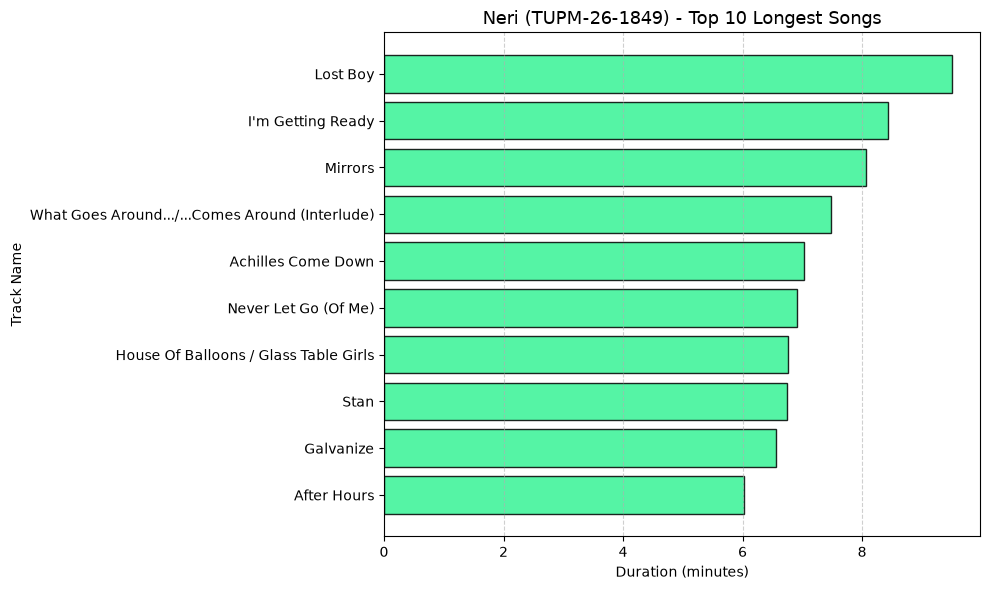

In [9]:
# Sort by duration_min descending and select top 10
top10_longest = (
    df.dropna(subset=["track_name", "artist", "duration_min"])
    .sort_values(by="duration_min", ascending=False)
    .head(10)
    .copy()
)

# Display table of track name, artist, and duration
longest_table = top10_longest[["track_name", "artist", "duration_min"]].reset_index(drop=True)
longest_table.index = longest_table.index + 1
print("=== Top 10 Longest Tracks ===")
print(longest_table.to_string())

# Horizontal bar chart with longest track at the top
plot_df = top10_longest.iloc[::-1]

plt.figure(figsize=(10, 6))
plt.barh(
    plot_df["track_name"],
    plot_df["duration_min"],
    color=color_bar,
    edgecolor="black",
    alpha=0.85,
)
plt.title(f"{student_name} ({student_id}) - Top 10 Longest Songs", fontsize=13)
plt.xlabel("Duration (minutes)")
plt.ylabel("Track Name")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


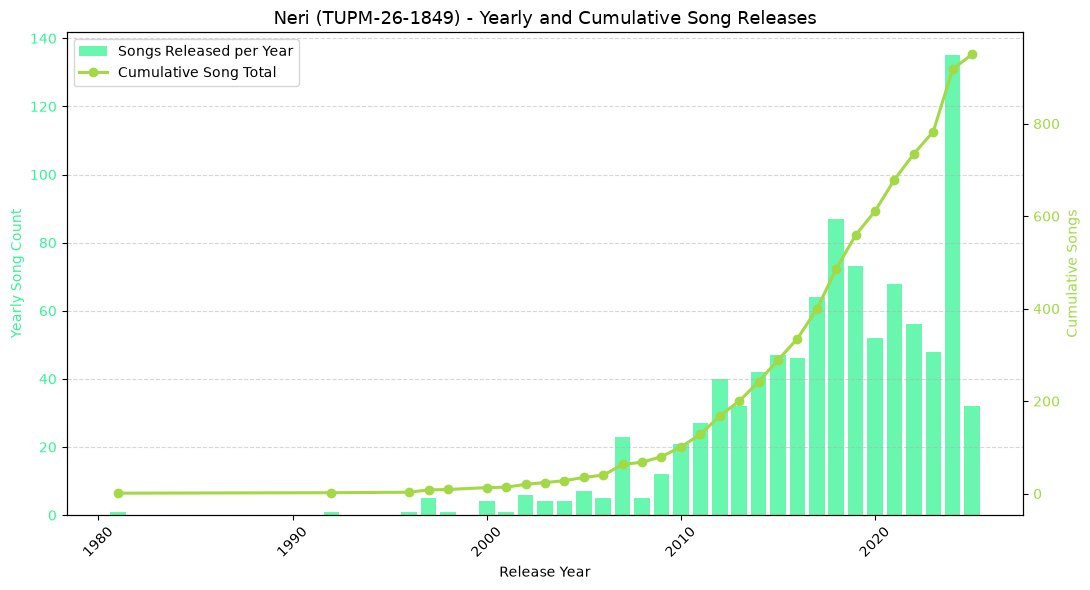

In [10]:
# Group by year and compute cumulative song count
yearly_counts = (
    df.dropna(subset=["year"])
    .loc[lambda d: d["year"] > 0]
    .groupby("year")["track_name"]
    .count()
    .sort_index()
)

release_trend = pd.DataFrame({
    "yearly_count": yearly_counts,
    "cumulative_count": yearly_counts.cumsum(),
})

# Combined bar (yearly count) + line (cumulative count) chart
fig, ax1 = plt.subplots(figsize=(11, 6))

ax1.bar(
    release_trend.index.astype(int),
    release_trend["yearly_count"],
    color=color_bar,
    alpha=0.75,
    label="Songs Released per Year",
)
ax1.set_xlabel("Release Year")
ax1.set_ylabel("Yearly Song Count", color=color_bar)
ax1.tick_params(axis="y", labelcolor=color_bar)
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(
    release_trend.index.astype(int),
    release_trend["cumulative_count"],
    color=color_line,
    marker="o",
    linewidth=2.2,
    label="Cumulative Song Total",
)
ax2.set_ylabel("Cumulative Songs", color=color_line)
ax2.tick_params(axis="y", labelcolor=color_line)

plt.title(f"{student_name} ({student_id}) - Yearly and Cumulative Song Releases", fontsize=13)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()


In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.animation import FuncAnimation, PillowWriter

# Filter valid rows and get sorted release years
hex_df = (
    df.dropna(subset=["duration_min", "popularity", "year"])
    .loc[lambda d: d["year"] > 0]
    .sort_values("year")
    .copy()
)

years = sorted(hex_df["year"].astype(int).unique())
x_min, x_max = float(hex_df["duration_min"].min()), float(hex_df["duration_min"].max())
y_min, y_max = float(hex_df["popularity"].min()), float(hex_df["popularity"].max())

# Compute max bin count across all years so colorbar scale stays valid and steady
full_hb_temp = plt.hexbin(
    hex_df["duration_min"],
    hex_df["popularity"],
    gridsize=18,
    mincnt=1,
    extent=(x_min, x_max, y_min, y_max),
)
max_count = max(2, int(full_hb_temp.get_array().max())) if len(full_hb_temp.get_array()) > 0 else 10
plt.close()

norm = Normalize(vmin=1, vmax=max_count)

fig, ax = plt.subplots(figsize=(9, 6))
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel("Duration (minutes)")
ax.set_ylabel("Popularity Score")
ax.grid(True, linestyle="--", alpha=0.4)

# Initial hexbin plot with fixed normalization
first_subset = hex_df[hex_df["year"] <= years[0]]
hb = ax.hexbin(
    first_subset["duration_min"],
    first_subset["popularity"],
    gridsize=18,
    cmap=cmap_color,
    norm=norm,
    mincnt=1,
    extent=(x_min, x_max, y_min, y_max),
)
fig.colorbar(hb, ax=ax, label="Song Density (Count)")
title_obj = ax.set_title(
    f"{student_name} ({student_id}) - Duration vs. Popularity Density (Through {years[0]})",
    fontsize=12,
)

def update(frame_idx):
    global hb
    current_year = years[frame_idx]
    subset = hex_df[hex_df["year"] <= current_year]

    hb.remove()
    hb = ax.hexbin(
        subset["duration_min"],
        subset["popularity"],
        gridsize=18,
        cmap=cmap_color,
        norm=norm,
        mincnt=1,
        extent=(x_min, x_max, y_min, y_max),
    )
    title_obj.set_text(
        f"{student_name} ({student_id}) - Duration vs. Popularity Density (Through {current_year})"
    )
    return hb, title_obj

plt.tight_layout()
ani = FuncAnimation(fig, update, frames=len(years), interval=250, blit=False, repeat=False)

gif_path = os.path.abspath("duration_popularity_density_evolution.gif")
ani.save(gif_path, writer=PillowWriter(fps=4))
plt.close(fig)
print(f"Animation saved to: {gif_path}")


Animation saved to: c:\Users\james\Documents\Lab8_Data_Visualization_Neri\duration_popularity_density_evolution.gif
